<a href="https://colab.research.google.com/github/AndresAvella09/Proyecto_Multimodal/blob/main/notebooks/11_buscador_adaptado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 11 · Buscador: adaptar la representación con entrenamiento

Hasta ahora el buscador usa los modelos **tal cual vienen** (CLIP para el póster, E5 para la sinopsis).
Aquí se entrena una **capa pequeña** encima de los vectores de cada película para que el espacio
entienda mejor los géneros de cine. Es el flujo que pide la guía del proyecto:

> **representación inicial** (CLIP / E5 congelados) → **entrenamiento** (adaptador) → **representación final** → **efecto en la tarea** (búsqueda)

### La idea, en simple

Cada película es un punto en el espacio de vectores, y cada búsqueda también. Buscar = encontrar los puntos más cercanos.
El adaptador **mueve un poco los puntos de las películas** para que las de terror queden más cerca de la frase
"terror", las animadas más cerca de "animación", etc. Las búsquedas **no se tocan**: se siguen codificando igual
que en el notebook 10. Por eso cualquier búsqueda libre ("una casa embrujada en la nieve") sigue funcionando.

### Cómo se evita hacer trampa

1. **Películas distintas:** el adaptador se entrena con las películas de `train`, se ajusta con `dev`
   y se evalúa **solo con las de `test`**, que nunca vio.
2. **Frases distintas:** se entrena con frases como *"cine de terror"* o *"a horror story"*, y se evalúa con las frases
   del notebook 10 (*"una película de terror"*, *"a horror movie"*).
3. **Se mide si se daña lo demás:** para búsquedas libres que no son de género, se compara qué tanto cambian los resultados.

| Sección | Qué hace | Archivos |
|---|---|---|
| 1 | Carga datos, vectores y modelos | — |
| 2 | Frases de entrenamiento | — |
| 3 | El adaptador y su entrenamiento (3 semillas por modalidad) | `modelos/adaptador_*.pt` |
| 4 | Efecto en la búsqueda: antes vs. después (en `test`) | `resultados/adaptado_*.csv` |
| 5 | La representación antes vs. después (mapas UMAP y vecinos) | — |
| 6 | ¿Se dañan las búsquedas libres? | — |
| 7 | Guardar los vectores adaptados para la página web | `embeddings/*_adapt.npy` |



In [1]:
import os, sys, io, json, copy
import numpy as np, pandas as pd, matplotlib.pyplot as plt

EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    !pip install -q sentence-transformers umap-learn

BASE = os.environ.get('PM_BASE', '/content/drive/MyDrive/proyecto_multimodal')
DATA, EMB, RES, MOD = f'{BASE}/data', f'{BASE}/embeddings', f'{BASE}/resultados', f'{BASE}/modelos'
# Si los vectores quedaron en una subcarpeta embeddings/embeddings, usarla
if not os.path.exists(f'{EMB}/clip_img.npy') and os.path.exists(f'{EMB}/embeddings/clip_img.npy'):
    EMB = f'{EMB}/embeddings'
print('Vectores en:', EMB)
os.makedirs(RES, exist_ok=True); os.makedirs(MOD, exist_ok=True)

pelis = pd.read_parquet(f'{DATA}/mmimdb_con_anio.parquet')
assert (pelis['fila_hdf5'].values == np.arange(len(pelis))).all()
GENEROS = [c[4:] for c in pelis.columns if c.startswith('hoy_')]
Y = pelis[[f'hoy_{g}' for g in GENEROS]].values.astype(np.float32)
pelis['titulo'] = pelis['titulo'].fillna('(sin título)')
pelis['anio_txt'] = pelis['anio'].astype('Int64').astype(str).replace('<NA>', '?')

ok = pelis['etiquetas_hoy_ok'].fillna(False).values.astype(bool)
es_cine = pelis['es_pelicula'].fillna(False).values.astype(bool)
part = pelis['particion'].values
IDX = {p: np.where(ok & (part == p))[0] for p in ['train', 'dev']}
IDX['test'] = np.where(ok & es_cine & (part == 'test'))[0]          # catálogo de evaluación
print({k: len(v) for k, v in IDX.items()})

def l2(X):
    return X / np.linalg.norm(X, axis=1, keepdims=True).clip(min=1e-8)

V = {'poster': l2(np.load(f'{EMB}/clip_img.npy').astype(np.float32)),
     'sinopsis': l2(np.load(f'{EMB}/e5_txt.npy').astype(np.float32))}
POSTERS = pd.read_parquet(f'{DATA}/posters_mini.parquet')['jpg'].tolist()
print({k: v.shape for k, v in V.items()})

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'figure.dpi': 110})
AZUL, GRIS, NARANJA = '#2563eb', '#9ca3af', '#ea580c'

Mounted at /content/drive
Vectores en: /content/drive/MyDrive/proyecto_multimodal/embeddings
{'train': 15531, 'dev': 2599, 'test': 7090}
{'poster': (25959, 512), 'sinopsis': (25959, 768)}


In [2]:
import torch, torch.nn as nn, torch.nn.functional as F
from sentence_transformers import SentenceTransformer

device = 'cuda' if torch.cuda.is_available() else 'cpu'
modelo_clip = SentenceTransformer('sentence-transformers/clip-ViT-B-32-multilingual-v1', device=device)
modelo_e5 = SentenceTransformer('intfloat/multilingual-e5-base', device=device)

def codificar_clip(textos):
    return l2(modelo_clip.encode(textos, convert_to_numpy=True).astype(np.float32))

def codificar_e5(textos, tipo='query'):
    return modelo_e5.encode([f'{tipo}: {t}' for t in textos], convert_to_numpy=True,
                            normalize_embeddings=True).astype(np.float32)

# cada modalidad se busca con su propio codificador de texto (igual que en el notebook 10)
CODIF = {'poster': codificar_clip, 'sinopsis': codificar_e5}
print('Modelos listos en', device)

modules.json:   0%|          | 0.00/341 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/5.65k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/572 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  539MB            

... (21 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Modelos listos en cuda


## 2. Frases de entrenamiento

Para enseñarle al adaptador qué es "terror", se usan **8 frases por género** (4 en español, 4 en inglés)
**distintas** a las frases de evaluación del notebook 10. En cada paso del entrenamiento se elige una al azar,
así el adaptador no se aprende una frase en particular.

In [3]:
PALABRAS = {   # género: (español, inglés)
    'Drama': ('drama', 'drama'), 'Comedy': ('comedia', 'comedy'), 'Romance': ('romance', 'romance'),
    'Thriller': ('suspenso', 'thriller'), 'Crime': ('crimen', 'crime'), 'Action': ('acción', 'action'),
    'Adventure': ('aventuras', 'adventure'), 'Horror': ('terror', 'horror'),
    'Documentary': ('documental', 'documentary'), 'Mystery': ('misterio', 'mystery'),
    'Sci-Fi': ('ciencia ficción', 'science fiction'), 'Fantasy': ('fantasía', 'fantasy'),
    'Family': ('familia', 'family'), 'Biography': ('biografía', 'biography'), 'War': ('guerra', 'war'),
    'History': ('historia', 'history'), 'Music': ('música', 'music'), 'Animation': ('animación', 'animation'),
    'Musical': ('musical', 'musical'), 'Western': ('vaqueros', 'western'), 'Sport': ('deportes', 'sports'),
    'Short': ('cortometraje', 'short'), 'Film-Noir': ('cine negro', 'film noir'),
}
PLANTILLAS_ES = ['cine de {}', 'película del género {}', 'una historia de {}', 'filme de {}']
PLANTILLAS_EN = ['{} film', 'a {} story', 'movies in the {} genre', 'a classic {} picture']

frases_entr = [[p.format(PALABRAS[g][0]) for g in GENEROS] for p in PLANTILLAS_ES] + \
              [[p.format(PALABRAS[g][1]) for g in GENEROS] for p in PLANTILLAS_EN]
print('Ejemplo (Horror):', [f[GENEROS.index('Horror')] for f in frases_entr])

# (n_plantillas, n_géneros, dim) para cada modalidad
Q_ENTR = {m: np.stack([CODIF[m](f) for f in frases_entr]) for m in V}
print({m: q.shape for m, q in Q_ENTR.items()})

Ejemplo (Horror): ['cine de terror', 'película del género terror', 'una historia de terror', 'filme de terror', 'horror film', 'a horror story', 'movies in the horror genre', 'a classic horror picture']
{'poster': (8, 23, 512), 'sinopsis': (8, 23, 768)}


## 3. El adaptador

Es una capa lineal **residual**: al vector de la película se le suma una corrección y se vuelve a normalizar.

$$v' = \frac{v + W v}{\lVert v + W v \rVert}$$

- $W$ empieza en **cero**, así que al inicio $v' = v$: arranca exactamente desde la representación inicial.
- Un castigo $\lambda \lVert W \rVert^2$ evita que se aleje demasiado (para no dañar las búsquedas libres).

**Cómo aprende:** para cada película y cada género, el puntaje es la similitud coseno entre $v'$ y la frase del género
(multiplicada por una escala y con un sesgo por género). Se entrena con **entropía cruzada binaria multietiqueta**:
el puntaje debe ser alto para los géneros de la película y bajo para los demás.

Se entrena **un adaptador por modalidad** (póster y sinopsis), así se puede seguir midiendo cada una por separado
y combinarlas con `alfa` como en el notebook 10. Se usa `dev` para detener el entrenamiento (*early stopping*)
y se repite con **3 semillas**.

  poster semilla 0: 72 épocas | pérdida dev 0.2116 | similitud media con el vector original 0.793
  poster semilla 1: 52 épocas | pérdida dev 0.2137 | similitud media con el vector original 0.745
  poster semilla 2: 57 épocas | pérdida dev 0.2128 | similitud media con el vector original 0.758
sinopsis semilla 0: 74 épocas | pérdida dev 0.1926 | similitud media con el vector original 0.289
sinopsis semilla 1: 65 épocas | pérdida dev 0.1950 | similitud media con el vector original 0.290
sinopsis semilla 2: 73 épocas | pérdida dev 0.1929 | similitud media con el vector original 0.283


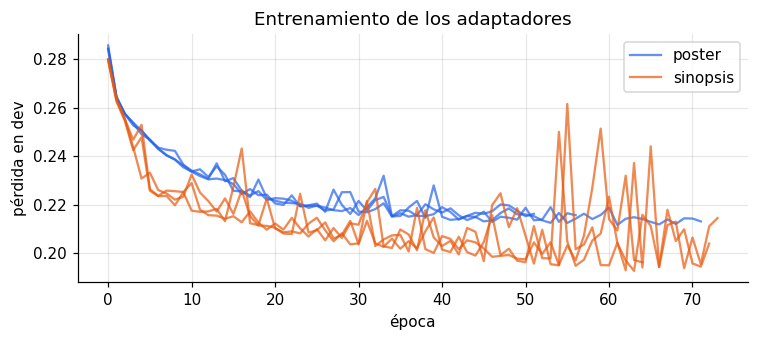

In [4]:
class Adaptador(nn.Module):
    def __init__(self, d, n_generos):
        super().__init__()
        self.W = nn.Linear(d, d, bias=False)
        nn.init.zeros_(self.W.weight)                        # empieza como identidad
        self.log_escala = nn.Parameter(torch.tensor(np.log(20.0), dtype=torch.float32))
        self.sesgo = nn.Parameter(torch.zeros(n_generos))

    def forward(self, v):
        return F.normalize(v + self.W(v), dim=-1)

    def logits(self, v, q):                                  # v: (B, d)  q: (G, d)
        return self.log_escala.exp() * self(v) @ q.T + self.sesgo


def entrenar(modalidad, semilla, lam=1e-3, lr=1e-3, epocas=60, lote=256, paciencia=6):
    torch.manual_seed(semilla); np.random.seed(semilla)
    X = torch.tensor(V[modalidad], device=device)
    Yt = torch.tensor(Y, device=device)
    Q = torch.tensor(Q_ENTR[modalidad], device=device)          # (P, G, d)
    P = Q.shape[0]
    tr, dv = torch.tensor(IDX['train'], device=device), torch.tensor(IDX['dev'], device=device)

    modelo = Adaptador(X.shape[1], len(GENEROS)).to(device)
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    mejor, mejor_estado, sin_mejora, hist = np.inf, None, 0, []

    for ep in range(epocas):
        modelo.train()
        for b in tr[torch.randperm(len(tr), device=device)].split(lote):
            q = Q[torch.randint(P, (len(GENEROS),), device=device), torch.arange(len(GENEROS), device=device)]
            perdida = F.binary_cross_entropy_with_logits(modelo.logits(X[b], q), Yt[b]) \
                      + lam * modelo.W.weight.pow(2).sum()
            opt.zero_grad(); perdida.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)   # evita pasos demasiado grandes
            opt.step()

        modelo.eval()
        with torch.no_grad():   # pérdida en dev promediando las 8 frases
            p_dev = np.mean([F.binary_cross_entropy_with_logits(modelo.logits(X[dv], Q[p]), Yt[dv]).item()
                             for p in range(P)])
        hist.append(p_dev)
        if p_dev < mejor - 1e-4:
            mejor, mejor_estado, sin_mejora = p_dev, copy.deepcopy(modelo.state_dict()), 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break

    modelo.load_state_dict(mejor_estado)
    with torch.no_grad():
        V_adapt = modelo(X).cpu().numpy()
    return modelo, V_adapt, hist


SEMILLAS = [0, 1, 2]
CONFIG = {'poster':   dict(lr=1e-3, epocas=150, paciencia=10),
          'sinopsis': dict(lr=3e-4, epocas=150, paciencia=10)}
adaptados, historias = {}, {}
for m in V:
    for s in SEMILLAS:
        modelo, V_adapt, hist = entrenar(m, s, **CONFIG[m])
        adaptados[(m, s)], historias[(m, s)] = V_adapt, hist
        torch.save(modelo.state_dict(), f'{MOD}/adaptador_{m}_s{s}.pt')
        cambio = np.mean(np.sum(V_adapt * V[m], axis=1))
        print(f'{m:>8} semilla {s}: {len(hist):>2} épocas | pérdida dev {min(hist):.4f} | '
              f'similitud media con el vector original {cambio:.3f}')

fig, ax = plt.subplots(figsize=(7, 3.2))
for (m, s), h in historias.items():
    ax.plot(h, color=AZUL if m == 'poster' else NARANJA, alpha=0.7, label=m if s == 0 else None)
ax.set_xlabel('época'); ax.set_ylabel('pérdida en dev'); ax.set_title('Entrenamiento de los adaptadores')
ax.legend(); plt.tight_layout(); plt.show()

## 4. Efecto en la búsqueda: antes vs. después

Las mismas 88 búsquedas del notebook 10 (frases y palabras, en español e inglés), ahora **solo sobre las películas de `test`**.
"Antes" usa los vectores originales y "después" los adaptados (promedio de las 3 semillas; el IC es por bootstrap sobre géneros).

In [5]:
from sklearn.metrics import average_precision_score

CONSULTAS = {   # las del notebook 10: (frase es, palabra es, frase en, palabra en)
    'Drama': ('una película dramática', 'drama', 'a drama movie', 'drama'),
    'Comedy': ('una película de comedia', 'comedia', 'a comedy movie', 'comedy'),
    'Romance': ('una película romántica', 'romance', 'a romantic movie', 'romance'),
    'Thriller': ('una película de suspenso', 'suspenso', 'a thriller movie', 'thriller'),
    'Crime': ('una película de crimen', 'crimen', 'a crime movie', 'crime'),
    'Action': ('una película de acción', 'acción', 'an action movie', 'action'),
    'Adventure': ('una película de aventuras', 'aventura', 'an adventure movie', 'adventure'),
    'Horror': ('una película de terror', 'terror', 'a horror movie', 'horror'),
    'Documentary': ('un documental', 'documental', 'a documentary', 'documentary'),
    'Mystery': ('una película de misterio', 'misterio', 'a mystery movie', 'mystery'),
    'Sci-Fi': ('una película de ciencia ficción', 'ciencia ficción', 'a science fiction movie', 'sci-fi'),
    'Fantasy': ('una película de fantasía', 'fantasía', 'a fantasy movie', 'fantasy'),
    'Family': ('una película familiar', 'familia', 'a family movie', 'family'),
    'Biography': ('una película biográfica', 'biografía', 'a biographical movie', 'biography'),
    'War': ('una película de guerra', 'guerra', 'a war movie', 'war'),
    'History': ('una película histórica', 'historia', 'a historical movie', 'history'),
    'Music': ('una película sobre música', 'música', 'a movie about music', 'music'),
    'Animation': ('una película animada', 'animación', 'an animated movie', 'animation'),
    'Musical': ('un musical', 'musical', 'a musical', 'musical'),
    'Western': ('una película del oeste', 'vaqueros', 'a western movie', 'western'),
    'Sport': ('una película de deportes', 'deportes', 'a sports movie', 'sports'),
    'Short': ('un cortometraje', 'corto', 'a short film', 'short'),
    'Film-Noir': ('una película de cine negro', 'cine negro', 'a film noir', 'noir'),
}
TIPOS = [('es', 'frase'), ('es', 'palabra'), ('en', 'frase'), ('en', 'palabra')]

T = IDX['test']
Y_T = Y[T]
n_pos = pd.Series(Y_T.sum(axis=0), index=GENEROS)
GEN_EVAL = [g for g in GENEROS if n_pos[g] >= 20]
print(f'Catálogo de evaluación: {len(T):,} películas de test | géneros evaluados: {len(GEN_EVAL)} '
      f'(fuera: { {g: int(n_pos[g]) for g in GENEROS if g not in GEN_EVAL} })')

consultas = pd.DataFrame([{'genero': g, 'idioma': i, 'tipo': t, 'texto': CONSULTAS[g][k]}
                          for g in GEN_EVAL for k, (i, t) in enumerate(TIPOS)])
Q_EVAL = {m: CODIF[m](consultas['texto'].tolist()) for m in V}
gi = np.array([GENEROS.index(g) for g in consultas['genero']])

def zscore(S):
    return (S - S.mean(axis=-1, keepdims=True)) / (S.std(axis=-1, keepdims=True) + 1e-8)

def puntajes_eval(Vp, Vs, modo, alfa=0.5):
    # Vp, Vs: vectores de póster y sinopsis del catálogo de test
    sp, ss = Q_EVAL['poster'] @ Vp.T, Q_EVAL['sinopsis'] @ Vs.T
    return {'poster': sp, 'sinopsis': ss, 'ambos': alfa * zscore(sp) + (1 - alfa) * zscore(ss)}[modo]

def metricas(S):
    filas = []
    for i in range(len(S)):
        y = Y_T[:, gi[i]]; orden = np.argsort(-S[i])
        filas.append({'p@10': y[orden[:10]].mean(), 'AP': average_precision_score(y, S[i])})
    return pd.concat([consultas, pd.DataFrame(filas)], axis=1)

MODOS = ['poster', 'sinopsis', 'ambos']
versiones = {'antes': (V['poster'][T], V['sinopsis'][T])}
for s in SEMILLAS:
    versiones[f'después_s{s}'] = (adaptados[('poster', s)][T], adaptados[('sinopsis', s)][T])

res = []
for ver, (Vp, Vs) in versiones.items():
    for m in MODOS:
        r = metricas(puntajes_eval(Vp, Vs, m)); r['version'], r['modo'] = ver, m
        res.append(r)
res = pd.concat(res, ignore_index=True)
res['etapa'] = np.where(res['version'] == 'antes', 'antes', 'después')
res.to_csv(f'{RES}/adaptado_por_consulta.csv', index=False)

# por género: promedio de sus 4 búsquedas (y, en 'después', de las 3 semillas)
por_gen = res.groupby(['etapa', 'modo', 'genero'])[['p@10', 'AP']].mean().reset_index()

Catálogo de evaluación: 7,090 películas de test | géneros evaluados: 22 (fuera: {'Short': 0})


In [6]:
rng = np.random.default_rng(42)
B = 2000

def ic(x):
    medias = rng.choice(x, size=(B, len(x)), replace=True).mean(axis=1)
    return x.mean(), *np.percentile(medias, [2.5, 97.5])

filas = []
for m in MODOS:
    for etapa in ['antes', 'después']:
        d = por_gen[(por_gen.etapa == etapa) & (por_gen.modo == m)].set_index('genero').loc[GEN_EVAL]
        f = {'modo': m, 'etapa': etapa}
        for col in ['p@10', 'AP']:
            mu, lo, hi = ic(d[col].values)
            f[col if col != 'AP' else 'mAP'] = f'{mu:.3f} [{lo:.3f}, {hi:.3f}]'
        filas.append(f)
    # diferencia pareada después − antes
    a = por_gen[(por_gen.etapa == 'antes') & (por_gen.modo == m)].set_index('genero').loc[GEN_EVAL, 'AP'].values
    b = por_gen[(por_gen.etapa == 'después') & (por_gen.modo == m)].set_index('genero').loc[GEN_EVAL, 'AP'].values
    mu, lo, hi = ic(b - a)
    filas.append({'modo': m, 'etapa': 'diferencia', 'mAP': f'{mu:+.3f} [{lo:+.3f}, {hi:+.3f}]',
                  'p@10': f'mejora en {(b > a).sum()}/{len(a)} géneros'})
tabla = pd.DataFrame(filas)
tabla.to_csv(f'{RES}/adaptado_resumen.csv', index=False)

# variación entre semillas (¿el resultado depende de la semilla?)
sem = (res[res.etapa == 'después'].groupby(['modo', 'version', 'genero'])['AP'].mean()
       .groupby(['modo', 'version']).mean().groupby('modo').agg(['mean', 'std']))
print('mAP después, entre semillas (media ± desv. estándar):')
print(sem.loc[MODOS].round(4).to_string(), '\n')
tabla

mAP después, entre semillas (media ± desv. estándar):
            mean     std
modo                    
poster    0.3729  0.0005
sinopsis  0.4534  0.0013
ambos     0.5126  0.0017 



,modo,etapa,p@10,mAP
0,poster,antes,"0.417 [0.309, 0.522]","0.209 [0.149, 0.276]"
1,poster,después,"0.672 [0.569, 0.774]","0.373 [0.289, 0.461]"
2,poster,diferencia,mejora en 22/22 géneros,"+0.164 [+0.131, +0.202]"
3,sinopsis,antes,"0.533 [0.425, 0.641]","0.226 [0.164, 0.288]"
4,sinopsis,después,"0.728 [0.626, 0.823]","0.453 [0.369, 0.542]"
5,sinopsis,diferencia,mejora en 22/22 géneros,"+0.227 [+0.188, +0.263]"
6,ambos,antes,"0.560 [0.443, 0.665]","0.272 [0.211, 0.338]"
7,ambos,después,"0.766 [0.664, 0.864]","0.513 [0.426, 0.599]"
8,ambos,diferencia,mejora en 22/22 géneros,"+0.241 [+0.200, +0.284]"


   antes: mejor alfa = 0.5 (mAP 0.272) | solo sinopsis 0.226 | solo póster 0.209
 después: mejor alfa = 0.4 (mAP 0.518) | solo sinopsis 0.453 | solo póster 0.373


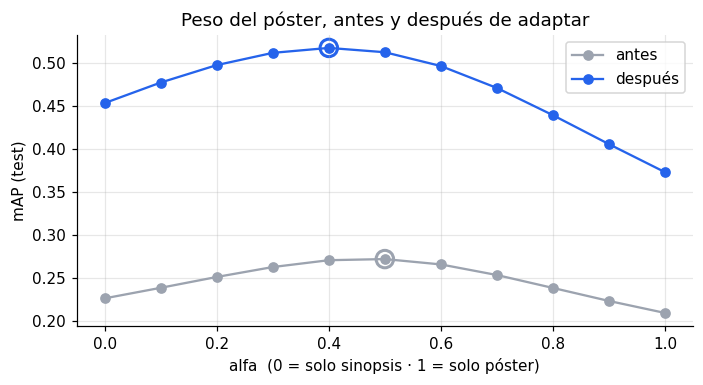

In [7]:
# ¿Cambia el mejor peso del póster después de adaptar?
ALFAS = np.round(np.arange(0, 1.01, 0.1), 1)
filas = []
for etapa, vers in [('antes', ['antes']), ('después', [f'después_s{s}' for s in SEMILLAS])]:
    for a in ALFAS:
        m_ap = np.mean([metricas(puntajes_eval(*versiones[v], 'ambos', a)).groupby('genero')['AP'].mean().mean()
                        for v in vers])
        filas.append({'etapa': etapa, 'alfa': a, 'mAP': m_ap})
barrido = pd.DataFrame(filas)
barrido.to_csv(f'{RES}/adaptado_alfa.csv', index=False)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for etapa, color in [('antes', GRIS), ('después', AZUL)]:
    d = barrido[barrido.etapa == etapa]
    ax.plot(d['alfa'], d['mAP'], marker='o', color=color, label=etapa)
    mejor = d.loc[d['mAP'].idxmax()]
    ax.scatter([mejor['alfa']], [mejor['mAP']], s=130, facecolors='none', edgecolors=color, lw=2)
    print(f"{etapa:>8}: mejor alfa = {mejor['alfa']:.1f} (mAP {mejor['mAP']:.3f}) | "
          f"solo sinopsis {d.iloc[0]['mAP']:.3f} | solo póster {d.iloc[-1]['mAP']:.3f}")
ax.set_xlabel('alfa  (0 = solo sinopsis · 1 = solo póster)'); ax.set_ylabel('mAP (test)')
ax.set_title('Peso del póster, antes y después de adaptar'); ax.legend()
plt.tight_layout(); plt.show()

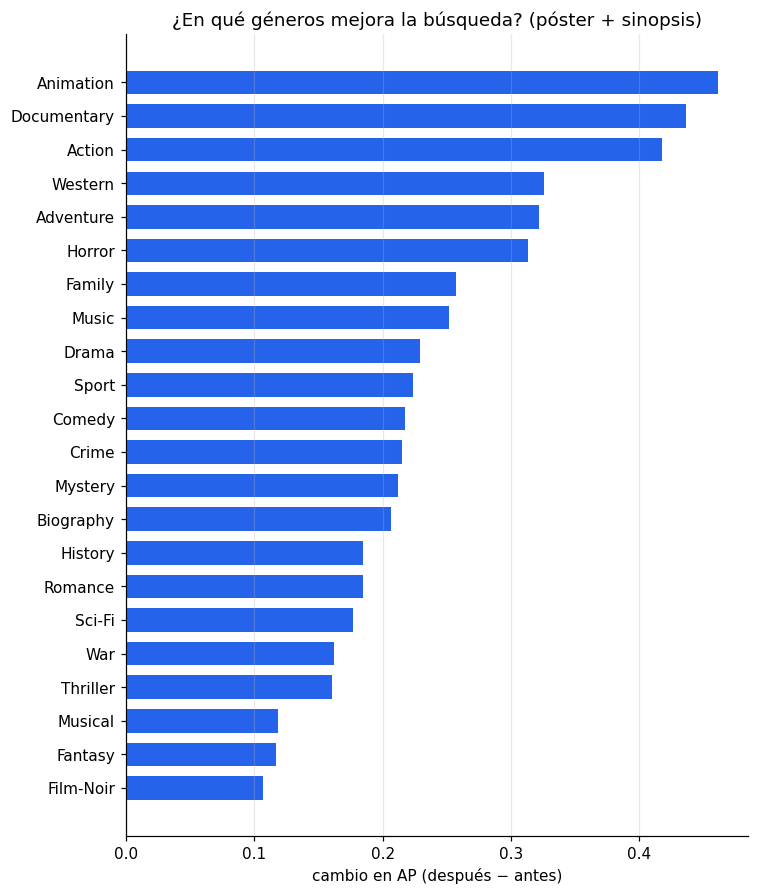

etapa        antes  después  cambio
genero                             
Film-Noir    0.016    0.122   0.107
Fantasy      0.150    0.268   0.117
Musical      0.085    0.203   0.119
Thriller     0.212    0.372   0.160
War          0.223    0.385   0.162
Sci-Fi       0.353    0.530   0.177
Romance      0.422    0.607   0.185
History      0.117    0.302   0.185
Biography    0.132    0.338   0.207
Mystery      0.152    0.364   0.212
Crime        0.442    0.657   0.215
Comedy       0.587    0.805   0.218
Sport        0.363    0.587   0.224
Drama        0.604    0.833   0.229
Music        0.257    0.509   0.252
Family       0.072    0.330   0.258
Horror       0.426    0.739   0.313
Adventure    0.275    0.596   0.322
Western      0.228    0.553   0.326
Action       0.273    0.691   0.418
Documentary  0.389    0.826   0.436
Animation    0.199    0.661   0.461


In [8]:
# Por género: ¿dónde ayuda más el adaptador? (modo 'ambos')
g = por_gen[por_gen.modo == 'ambos'].pivot(index='genero', columns='etapa', values='AP').loc[GEN_EVAL]
g['cambio'] = g['después'] - g['antes']
g = g.sort_values('cambio')

fig, ax = plt.subplots(figsize=(7, 0.32 * len(g) + 1.2))
ax.barh(g.index, g['cambio'], color=[AZUL if v > 0 else NARANJA for v in g['cambio']], height=0.7)
ax.axvline(0, color='black', lw=1)
ax.set_xlabel('cambio en AP (después − antes)')
ax.set_title('¿En qué géneros mejora la búsqueda? (póster + sinopsis)')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
print(g.round(3).to_string())

## 5. La representación antes vs. después

Dos formas de ver si el espacio de vectores cambió:

1. **Pureza de vecinos:** para cada película de `test`, ¿qué fracción de sus 10 vecinos más cercanos comparte
   al menos un género con ella? Si sube, las películas parecidas quedaron más juntas.
2. **Mapas UMAP:** se proyectan los vectores a 2D y se colorean por género, para películas con uno solo de
   6 géneros fáciles de distinguir.

In [9]:
from sklearn.neighbors import NearestNeighbors

def pureza_vecinos(Vx, Yx, k=10):
    nn_ = NearestNeighbors(n_neighbors=k + 1, metric='cosine').fit(Vx)
    vec = nn_.kneighbors(Vx, return_distance=False)[:, 1:]
    comparte = (Yx[vec] * Yx[:, None, :]).sum(axis=2) > 0          # (n, k)
    return comparte.mean()

azar = np.mean([(Y_T[np.random.default_rng(0).permutation(len(T))[:10]] * Y_T[i]).sum(1).clip(0, 1).mean()
                for i in range(0, len(T), 50)])
print(f'Pureza de vecinos (k=10) en test   | azar ≈ {azar:.3f}')
for m in V:
    antes = pureza_vecinos(V[m][T], Y_T)
    despues = np.mean([pureza_vecinos(adaptados[(m, s)][T], Y_T) for s in SEMILLAS])
    print(f'{m:>8}: antes {antes:.3f} → después {despues:.3f}  ({despues - antes:+.3f})')

Pureza de vecinos (k=10) en test   | azar ≈ 0.544
  poster: antes 0.707 → después 0.754  (+0.047)
sinopsis: antes 0.756 → después 0.827  (+0.071)


2,888 películas de test en el mapa


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


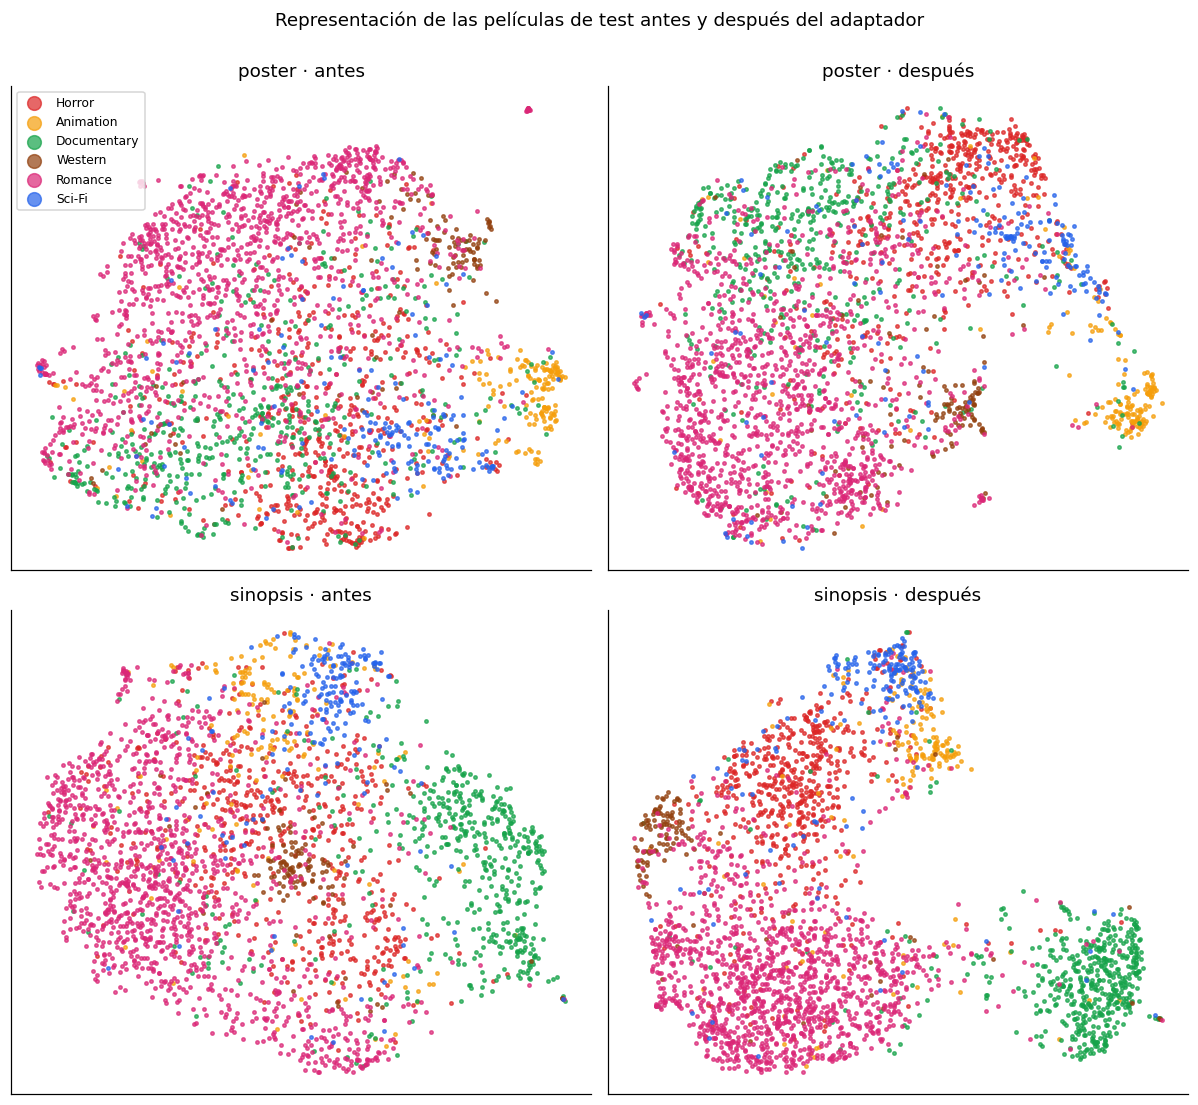

In [10]:
import umap

GEN_MAPA = ['Horror', 'Animation', 'Documentary', 'Western', 'Romance', 'Sci-Fi']
COLORES = ['#dc2626', '#f59e0b', '#16a34a', '#92400e', '#db2777', '#2563eb']
cols = [GENEROS.index(g) for g in GEN_MAPA]
uno = (Y_T[:, cols].sum(axis=1) == 1)                               # películas con uno solo de esos 6
sel = np.where(uno)[0]
etiqueta = np.array(GEN_MAPA)[Y_T[sel][:, cols].argmax(axis=1)]
print(f'{len(sel):,} películas de test en el mapa')

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for fila, m in enumerate(V):
    for col, (nombre, Vx) in enumerate([('antes', V[m][T][sel]), ('después', adaptados[(m, 0)][T][sel])]):
        xy = umap.UMAP(n_neighbors=15, min_dist=0.1, metric='cosine', random_state=42).fit_transform(Vx)
        ax = axes[fila, col]
        for gname, c in zip(GEN_MAPA, COLORES):
            k = etiqueta == gname
            ax.scatter(xy[k, 0], xy[k, 1], s=5, c=c, alpha=0.7, label=gname)
        ax.set_title(f'{m} · {nombre}'); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
axes[0, 0].legend(markerscale=4, fontsize=8, loc='best')
plt.suptitle('Representación de las películas de test antes y después del adaptador', y=1.0)
plt.tight_layout(); plt.show()

## 6. ¿Se dañan las búsquedas libres?

El adaptador aprendió géneros. El riesgo es que "olvide" otras cosas: si alguien busca *"princesas"* o
*"una casa embrujada en la nieve"*, ¿los resultados siguen teniendo sentido?

Se mide cuántas de las 10 primeras películas **se mantienen** después de adaptar (sobre todo el catálogo de cine),
y se muestran los pósters antes y después.

                      búsqueda  se mantienen (de 10)
                     princesas                     7
una casa embrujada en la nieve                     5
              a robot in space                     4
            un perro que habla                     6
     two cowboys in the desert                     6
         una boda que sale mal                     4
        a submarine in the war                     5
             piratas en el mar                     8


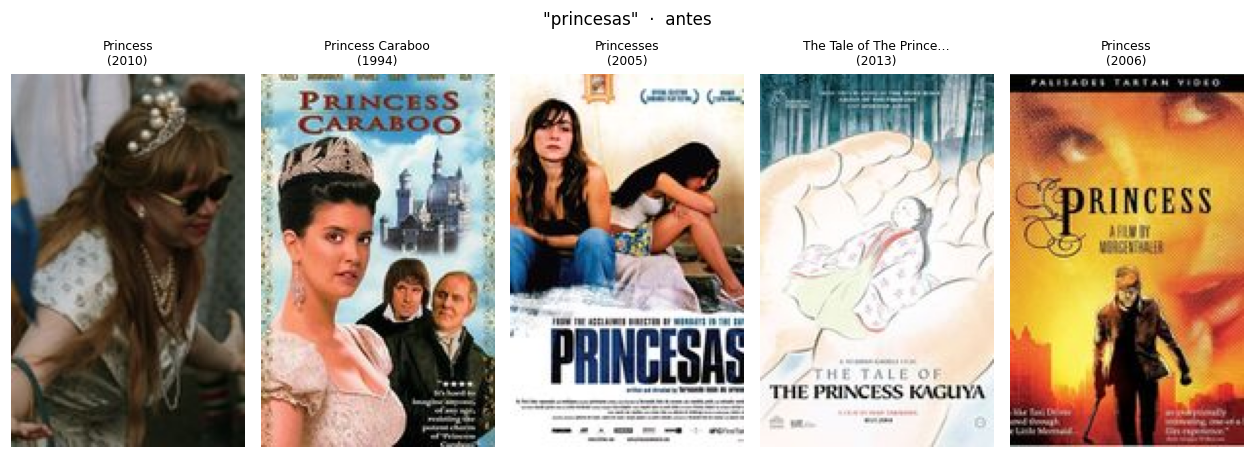

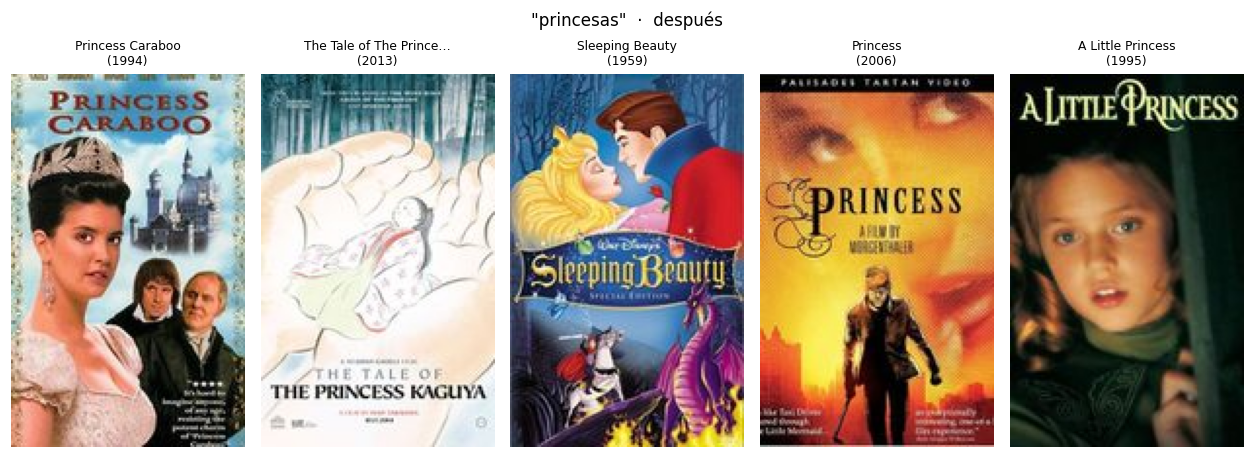

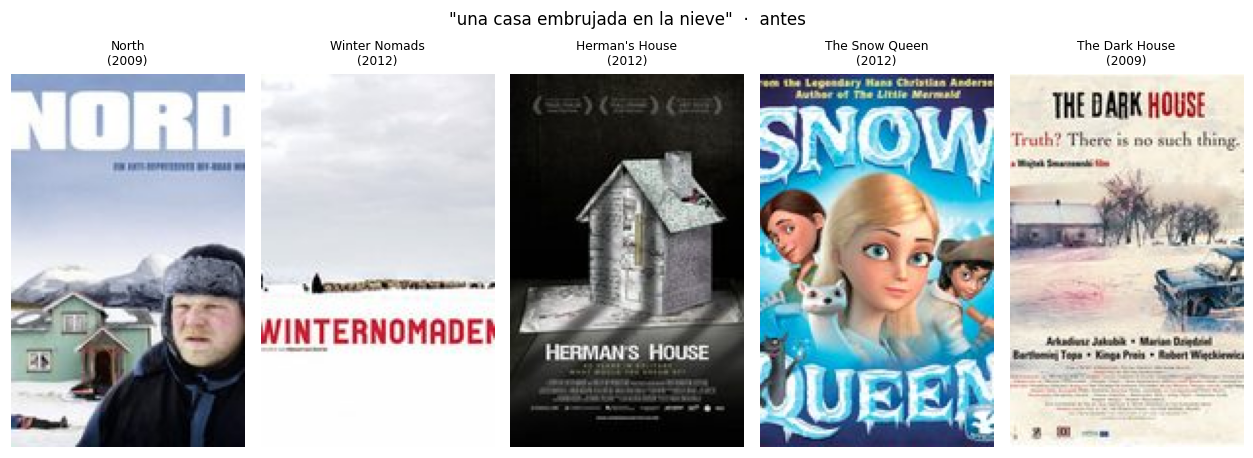

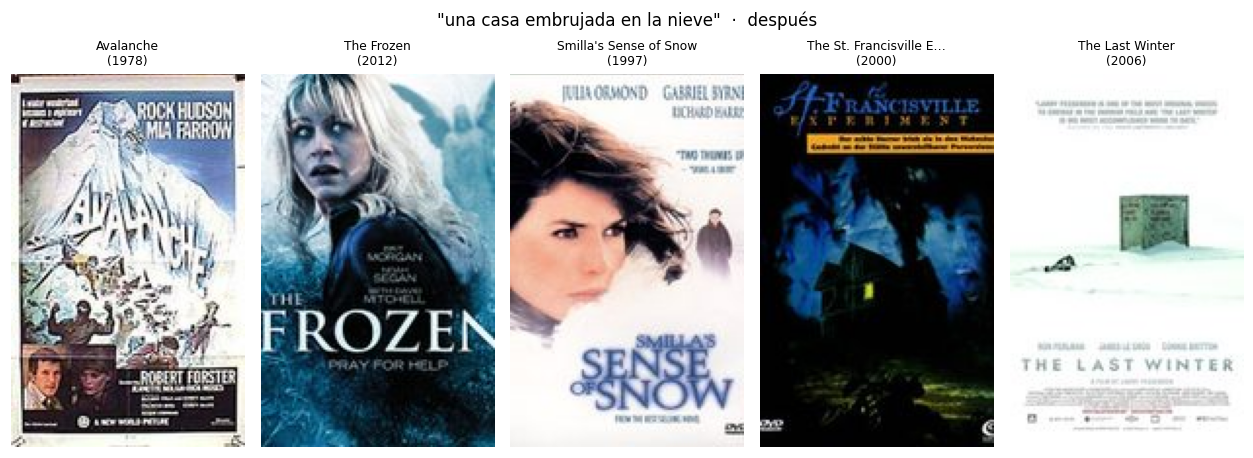

In [11]:
from PIL import Image

LIBRES = ['princesas', 'una casa embrujada en la nieve', 'a robot in space', 'un perro que habla',
          'two cowboys in the desert', 'una boda que sale mal', 'a submarine in the war', 'piratas en el mar']
CAT = np.where(es_cine)[0]

def top_libre(consulta, Vp, Vs, k=10, alfa=0.5):
    sp = CODIF['poster']([consulta])[0] @ Vp[CAT].T
    ss = CODIF['sinopsis']([consulta])[0] @ Vs[CAT].T
    s = alfa * zscore(sp) + (1 - alfa) * zscore(ss)
    return CAT[np.argsort(-s)[:k]]

Vp_a, Vs_a = adaptados[('poster', 0)], adaptados[('sinopsis', 0)]
filas = []
for c in LIBRES:
    a, d = top_libre(c, V['poster'], V['sinopsis']), top_libre(c, Vp_a, Vs_a)
    filas.append({'búsqueda': c, 'se mantienen (de 10)': len(set(a) & set(d))})
print(pd.DataFrame(filas).to_string(index=False))

def mostrar_idx(idx, titulo):
    fig, axes = plt.subplots(1, len(idx), figsize=(2.3 * len(idx), 4.4))
    for ax, i in zip(axes, idx):
        ax.imshow(Image.open(io.BytesIO(POSTERS[i]))); ax.axis('off')
        t = pelis.at[i, 'titulo']; t = t if len(t) <= 24 else t[:22] + '…'
        ax.set_title(f"{t}\n({pelis.at[i, 'anio_txt']})", fontsize=8)
    fig.suptitle(titulo, fontsize=11); plt.tight_layout(); plt.show()

for c in ['princesas', 'una casa embrujada en la nieve']:
    mostrar_idx(top_libre(c, V['poster'], V['sinopsis'], k=5), f'"{c}"  ·  antes')
    mostrar_idx(top_libre(c, Vp_a, Vs_a, k=5), f'"{c}"  ·  después')

## 7. Guardar para la página web

Se guardan los vectores adaptados (semilla 0) de **todas** las películas, en `float16` para que pesen la mitad.
La página web solo necesita estos vectores: las búsquedas se codifican igual que antes.

In [12]:
np.save(f'{EMB}/poster_adapt.npy', adaptados[('poster', 0)].astype(np.float16))
np.save(f'{EMB}/e5_adapt.npy', adaptados[('sinopsis', 0)].astype(np.float16))
print('Guardados poster_adapt.npy y e5_adapt.npy en', EMB)

Guardados poster_adapt.npy y e5_adapt.npy en /content/drive/MyDrive/proyecto_multimodal/embeddings


## Resumen

**Qué mirar en los resultados:**
1. **Sección 4:** ¿la diferencia *después − antes* del mAP es positiva y su IC no incluye el cero? ¿En cuántos géneros mejora?
2. **Peso del póster:** ¿cambia el mejor `alfa` después de adaptar? Si se mueve hacia el centro, el adaptador equilibró las dos modalidades.
3. **Sección 5:** ¿sube la pureza de vecinos? ¿Los colores del UMAP quedan más agrupados "después"?
4. **Sección 6:** ¿las búsquedas libres conservan la mayoría de sus resultados? Si se pierden casi todos, el adaptador se especializó demasiado
   en géneros y conviene subir `lam` (el castigo) en `entrenar`.

**Para el informe**, esto completa el flujo de la guía del proyecto:
representación inicial (CLIP / E5) → adaptador entrenado → representación final (UMAP, pureza de vecinos) → efecto en la tarea (mAP de búsqueda).